# Demo LIVE 1 · Un file che contiene solo dati mancanti


La mancanza non è neutra: la sola mappa di quali dati mancano riconosce il paziente.

Un modello vede solo quali celle sono vuote, nessun valore clinico.
Riuscirà a capire se il paziente è un uomo o una donna? Se i dati mancassero per caso, tirerebbe a indovinare: AUROC 0,5..

**I dati.** NHANES 2013-2014, l'indagine pubblica statunitense su salute e nutrizione: 6.113 adulti.

### Passo 1 · Un file di soli sì e no

Ogni cella dice solo se il dato c'è (`False`) oppure manca (`True`). Nessun valore clinico.

**Atteso:** 6.113 pazienti, 1.388 colonne.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

DATI = "https://raw.githubusercontent.com/MicheleFerramola00/lezioni/caf-unilink-m2.4/dati/"
M = pd.read_parquet(DATI + "mancanza_nhanes_adulti.parquet")
sesso = M.pop("sesso_F")                                   # 1 = donna, 0 = uomo
M = M.loc[:, (M.mean() > 0.01) & (M.mean() < 0.99)]       # via le colonne sempre piene o sempre vuote
print(f"{len(M)} pazienti, {M.shape[1]} colonne")
M.iloc[:5, :6]

6113 pazienti, 1388 colonne


,exam_period_6mo,age_months_at_exam,served_in_armed_conflict,years_in_us,education_6_19,education_20_plus
0,False,True,False,True,True,False
1,False,True,True,True,True,False
2,False,True,False,True,True,False
3,False,True,True,True,True,False
4,False,True,False,True,True,False


### Passo 2 · Un modello cerca di prevedere il sesso

Una regressione logistica impara sul 70% dei pazienti e viene testata sui restanti.

**Atteso:** AUROC 1,000. Non sbaglia mai.

In [13]:
scala = {}

def prova(colonne, descrizione):
    X_imp, X_ver, y_imp, y_ver = train_test_split(M[colonne], sesso, test_size=0.3, random_state=42, stratify=sesso)
    modello = LogisticRegression(max_iter=3000).fit(X_imp, y_imp)
    scala[descrizione] = roc_auc_score(y_ver, modello.predict_proba(X_ver)[:, 1])
    print(f"{descrizione:<50} AUROC {scala[descrizione]:.3f}   ({len(colonne)} colonne)")

prova(M.columns, "Tutte le colonne")

Tutte le colonne                                   AUROC 1.000   (1388 colonne)


### Passo 3 · Togliamo le variabili che suggeriscono il sesso

Sono domande che si fanno a un sesso solo. Le togliamo tutte per essere sicuri che il modello non le stia utilizzando come scorciatoie.

**Atteso:** AUROC 0,988. Quasi non cambia.

In [14]:
legate_al_sesso = [c for c in M.columns
                   if c.lower().startswith(("rh_", "vag_", "sx_", "imm_hpv"))
                   or any(p in c.lower() for p in ("prostat", "pregn", "menstr", "ovar", "hysterect"))]
prova(M.columns.drop(legate_al_sesso), "Senza gli argomenti legati al sesso")

Senza gli argomenti legati al sesso                AUROC 0.988   (1253 colonne)


### Passo 4 · Il filtro si stringe finché il segnale non sparisce

Tolgo ogni colonna in cui il dato manca più spesso a un sesso che all'altro, oltre una certa differenza in percentuale.


**Atteso:** 0,954 · 0,857 · 0,732 · 0,586, e 0,575 con il solo laboratorio.

Senza colonne con differenza oltre 30 punti        AUROC 0.954   (1254 colonne)
Senza colonne con differenza oltre 10 punti        AUROC 0.857   (1221 colonne)
Senza colonne con differenza oltre 5 punti         AUROC 0.732   (1125 colonne)
Senza colonne con differenza oltre 2 punti         AUROC 0.586   (970 colonne)


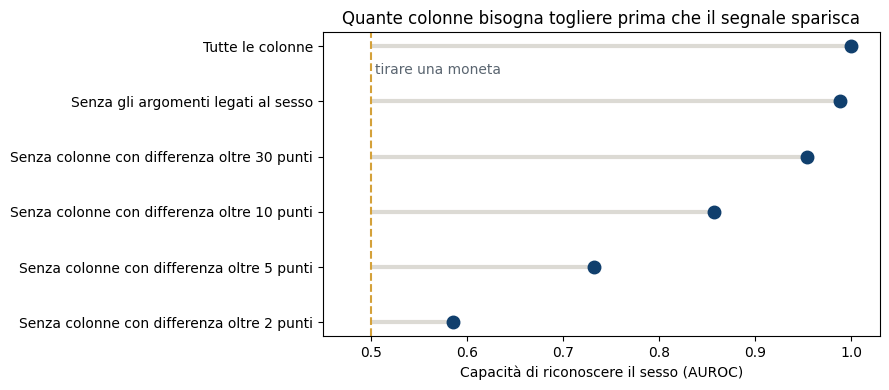

In [15]:
differenza = (M[sesso == 1].mean() - M[sesso == 0].mean()).abs()
for punti in (30, 10, 5, 2):
    prova(differenza.index[differenza <= punti / 100], f"Senza colonne con differenza oltre {punti} punti")

s = pd.Series(scala)[::-1]
ax = plt.figure(figsize=(9, 4)).gca()
ax.hlines(range(len(s)), 0.5, s, color="#dcdad4", lw=3)
ax.plot(s, range(len(s)), "o", color="#103F6D", ms=9)
ax.set_yticks(range(len(s)), s.index)
ax.axvline(0.5, color="#D4A13A", ls="--"); ax.text(0.505, len(s) - 1.5, "tirare una moneta", color="#5A6570")
ax.set_xlim(0.45, 1.03); ax.set_xlabel("Capacità di riconoscere il sesso (AUROC)")
ax.set_title("Quante colonne bisogna togliere prima che il segnale sparisca")
plt.tight_layout(); plt.show()

---

### Cosa abbiamo visto

1. **La sola mappa di ciò che manca identifica il paziente.**
2. **Togliere le variabili ovvie non basta:** il segnale è distribuito su centinaia di colonne, innocue da sole.
3. **Il segnale vive nel processo** (che cosa è stato chiesto, a chi, quando), non negli strumenti di laboratorio.

### Da chiedere in gara

> **Chi manca dal vostro dataset, e per quale meccanismo di selezione?**